## Project Overview
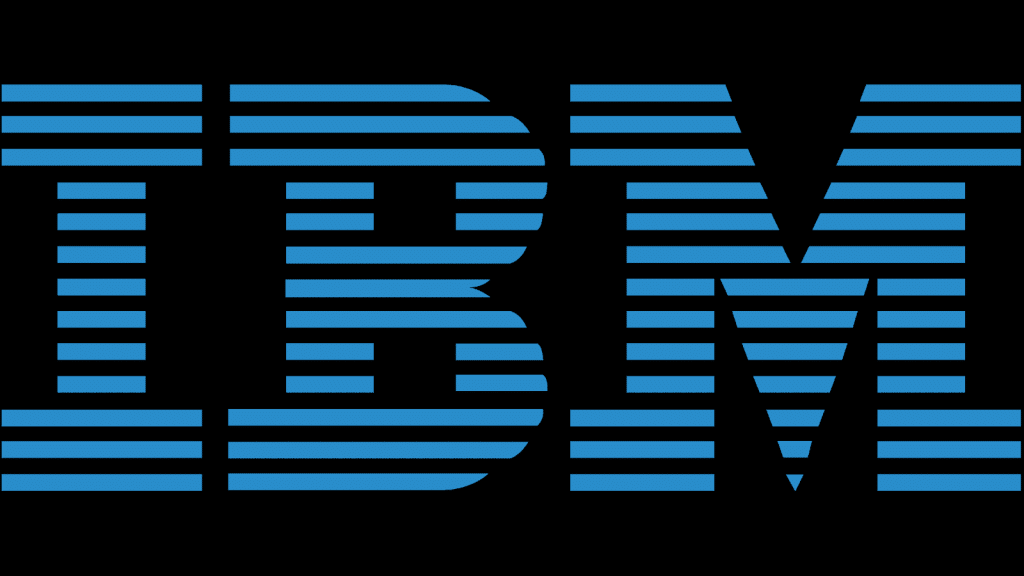
This project analyzes employee attrition using **Python, Pandas, Matplotlib, and Seaborn**.

The objective is to explore employee data and identify patterns associated with **employee attrition and turnover**. The analysis examines factors such as overtime, job role, job satisfaction, monthly income, age, work-life balance, business travel, job level, and years at the company.

The project includes **data exploration, data quality checks, statistical analysis, and data visualization** to understand differences in attrition rates across various employee and workplace factors.

The main goal is to transform employee data into **clear and meaningful HR insights** that can help understand employee attrition patterns and identify areas for further investigation.


In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [36]:
import os

print(os.listdir('/kaggle/input/datasets/paragchintanwar/ibm-hr'))

['IBM_HR_Analytics.csv']


In [37]:
import pandas as pd

df = pd.read_csv('/kaggle/input/datasets/paragchintanwar/ibm-hr/IBM_HR_Analytics.csv')

print(df.shape)
print(df.head())

(1470, 35)
   Age Attrition     BusinessTravel  DailyRate              Department  \
0   41       Yes      Travel_Rarely       1102                   Sales   
1   49        No  Travel_Frequently        279  Research & Development   
2   37       Yes      Travel_Rarely       1373  Research & Development   
3   33        No  Travel_Frequently       1392  Research & Development   
4   27        No      Travel_Rarely        591  Research & Development   

   DistanceFromHome  Education EducationField  EmployeeCount  EmployeeNumber  \
0                 1          2  Life Sciences              1               1   
1                 8          1  Life Sciences              1               2   
2                 2          2          Other              1               4   
3                 3          4  Life Sciences              1               5   
4                 2          1        Medical              1               7   

   ...  RelationshipSatisfaction StandardHours  StockOptionLeve

In [38]:
df.shape

(1470, 35)

In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [40]:
df.columns

Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='object')

# IBM HR PROJECT IIM 1 - DATACART

| Column | Description | Data Type | Example |
|---|---|---|---|
| `Age` | Employee's age | Integer | 41 |
| `Attrition` | Whether the employee left the company | String | Yes |
| `BusinessTravel` | Employee's travel frequency | String | Travel_Rarely |
| `Department` | Employee's department | String | Sales |
| `DistanceFromHome` | Distance between home and workplace | Integer | 1 |
| `Education` | Employee's education level | Integer | 2 |
| `EnvironmentSatisfaction` | Satisfaction with work environment | Integer | 3 |
| `JobInvolvement` | Employee's involvement in the job | Integer | 3 |
| `JobLevel` | Employee's job level | Integer | 2 |
| `JobRole` | Employee's job role | String | Sales Executive |
| `JobSatisfaction` | Employee's satisfaction with the job | Integer | 4 |
| `MonthlyIncome` | Employee's monthly income | Integer | 5993 |
| `NumCompaniesWorked` | Number of companies previously worked for | Integer | 8 |
| `OverTime` | Whether the employee works overtime | String | Yes |
| `PercentSalaryHike` | Percentage of salary increase | Integer | 11 |
| `PerformanceRating` | Employee's performance rating | Integer | 3 |
| `TotalWorkingYears` | Total years of work experience | Integer | 8 |
| `WorkLifeBalance` | Employee's work-life balance rating | Integer | 3 |
| `YearsAtCompany` | Number of years at the current company | Integer | 6 |
| `YearsInCurrentRole` | Years spent in the current role | Integer | 4 |
| `YearsSinceLastPromotion` | Years since the last promotion | Integer | 0 |
| `YearsWithCurrManager` | Years working with the current manager | Integer | 5 |

In [41]:
df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [42]:
df.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [43]:
df.duplicated().sum()

np.int64(0)

In [44]:
# Check duplicate rows
df.duplicated().sum()

np.int64(0)

In [45]:
# Check missing values
df.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [46]:
df['Attrition'].value_counts()

Attrition
No     1233
Yes     237
Name: count, dtype: int64

In [47]:
df['Attrition'].value_counts(normalize=True) * 100

Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64

In [48]:
pd.crosstab(df['OverTime'], df['Attrition'])

Attrition,No,Yes
OverTime,,
No,944,110
Yes,289,127


In [49]:
pd.crosstab(df['OverTime'], df['Attrition'], normalize='index') * 100

Attrition,No,Yes
OverTime,,
No,89.563567,10.436433
Yes,69.471154,30.528846


In [50]:
pd.crosstab(df['JobRole'], df['Attrition'], normalize='index') * 100

Attrition,No,Yes
JobRole,,
Healthcare Representative,93.129771,6.870229
Human Resources,76.923077,23.076923
Laboratory Technician,76.061776,23.938224
Manager,95.098039,4.901961
Manufacturing Director,93.103448,6.896552
Research Director,97.500000,2.500000
Research Scientist,83.904110,16.095890
Sales Executive,82.515337,17.484663
Sales Representative,60.240964,39.759036


In [51]:
pd.crosstab(df['JobSatisfaction'], df['Attrition'], normalize='index') * 100

Attrition,No,Yes
JobSatisfaction,,
1,77.162630,22.837370
2,83.571429,16.428571
3,83.484163,16.515837
4,88.671024,11.328976


In [52]:
df.groupby('Attrition')['MonthlyIncome'].mean()

Attrition
No     6832.739659
Yes    4787.092827
Name: MonthlyIncome, dtype: float64

In [53]:
df.groupby('Attrition')['Age'].mean()

Attrition
No     37.561233
Yes    33.607595
Name: Age, dtype: float64

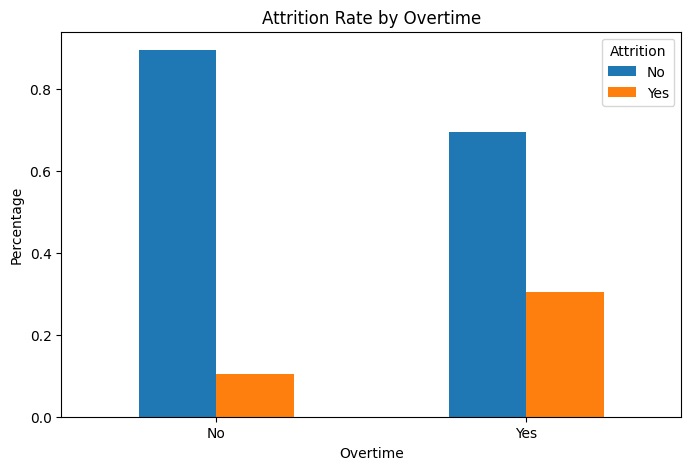

In [54]:
import matplotlib.pyplot as plt

pd.crosstab(df['OverTime'], df['Attrition'], normalize='index').plot(
    kind='bar',
    figsize=(8,5)
)

plt.title('Attrition Rate by Overtime')
plt.xlabel('Overtime')
plt.ylabel('Percentage')
plt.xticks(rotation=0)
plt.legend(title='Attrition')
plt.show()

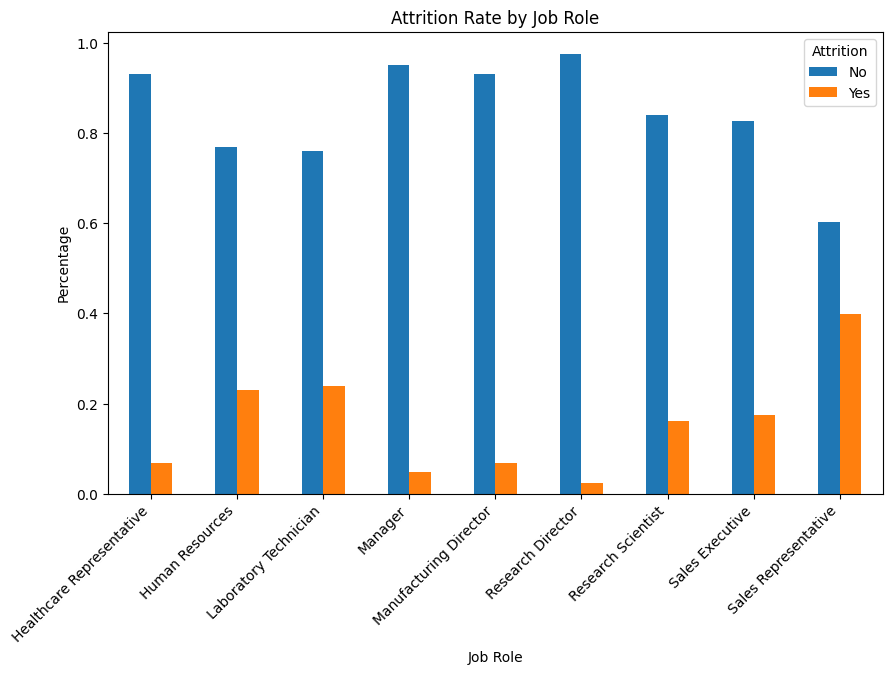

In [55]:
pd.crosstab(
    df['JobRole'],
    df['Attrition'],
    normalize='index'
).plot(
    kind='bar',
    figsize=(10,6)
)

plt.title('Attrition Rate by Job Role')
plt.xlabel('Job Role')
plt.ylabel('Percentage')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Attrition')
plt.show()

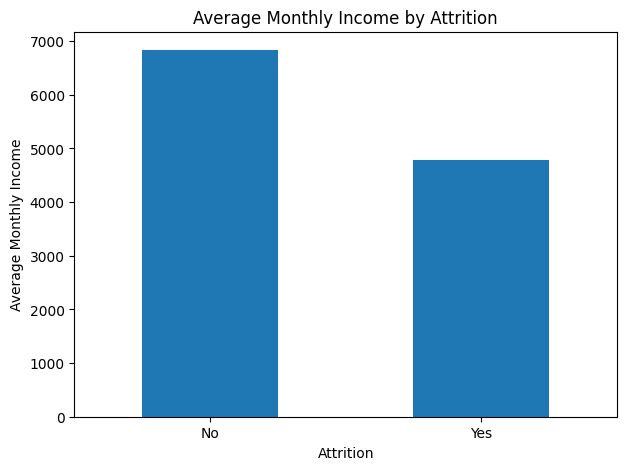

In [56]:
id="r8k2m1"
df.groupby('Attrition')['MonthlyIncome'].mean().plot(
    kind='bar',
    figsize=(7,5)
)

plt.title('Average Monthly Income by Attrition')
plt.xlabel('Attrition')
plt.ylabel('Average Monthly Income')
plt.xticks(rotation=0)
plt.show()

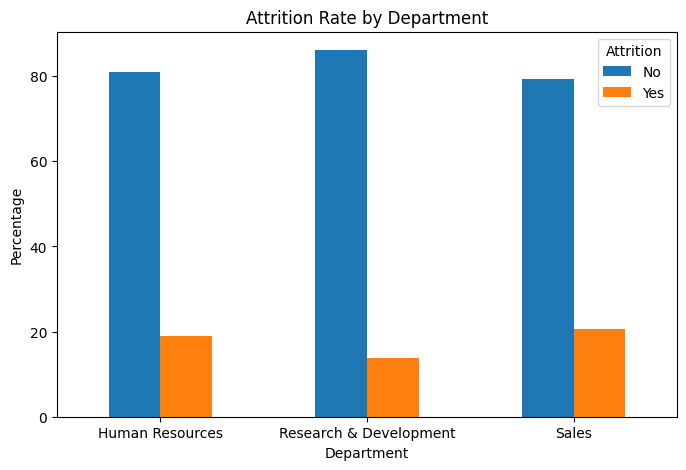

In [57]:
# Attrition Rate by Department

department_attrition = pd.crosstab(
    df['Department'],
    df['Attrition'],
    normalize='index'
) * 100

department_attrition.plot(
    kind='bar',
    figsize=(8,5)
)

plt.title('Attrition Rate by Department')
plt.xlabel('Department')
plt.ylabel('Percentage')
plt.xticks(rotation=0)
plt.legend(title='Attrition')
plt.show()

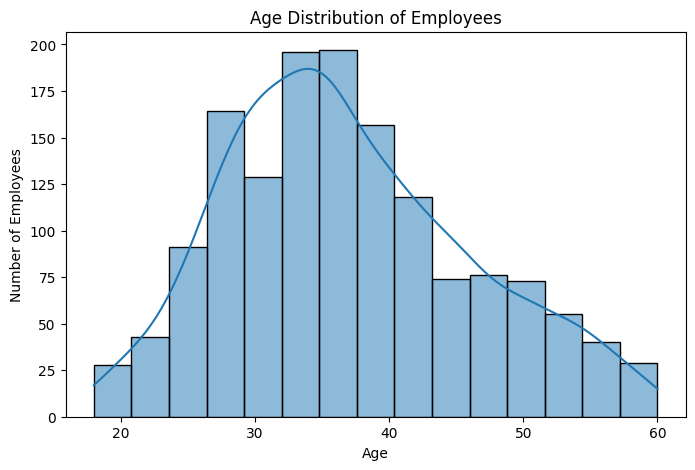

In [58]:
# Age Distribution of Employees

plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x='Age',
    bins=15,
    kde=True
)

plt.title('Age Distribution of Employees')
plt.xlabel('Age')
plt.ylabel('Number of Employees')
plt.show()

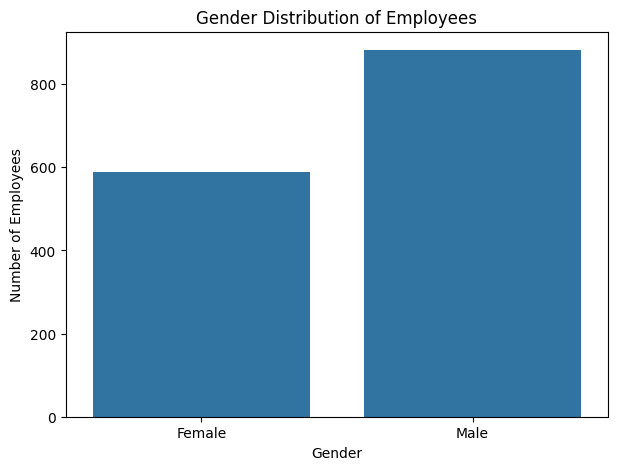

In [59]:
# Gender Distribution of Employees

plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x='Gender'
)

plt.title('Gender Distribution of Employees')
plt.xlabel('Gender')
plt.ylabel('Number of Employees')
plt.show()

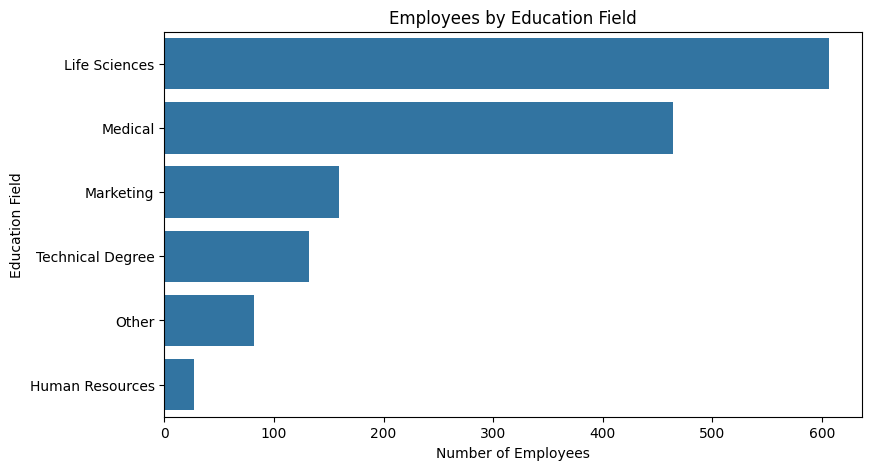

In [60]:
# Employees by Education Field

plt.figure(figsize=(9,5))

sns.countplot(
    data=df,
    y='EducationField',
    order=df['EducationField'].value_counts().index
)

plt.title('Employees by Education Field')
plt.xlabel('Number of Employees')
plt.ylabel('Education Field')
plt.show()

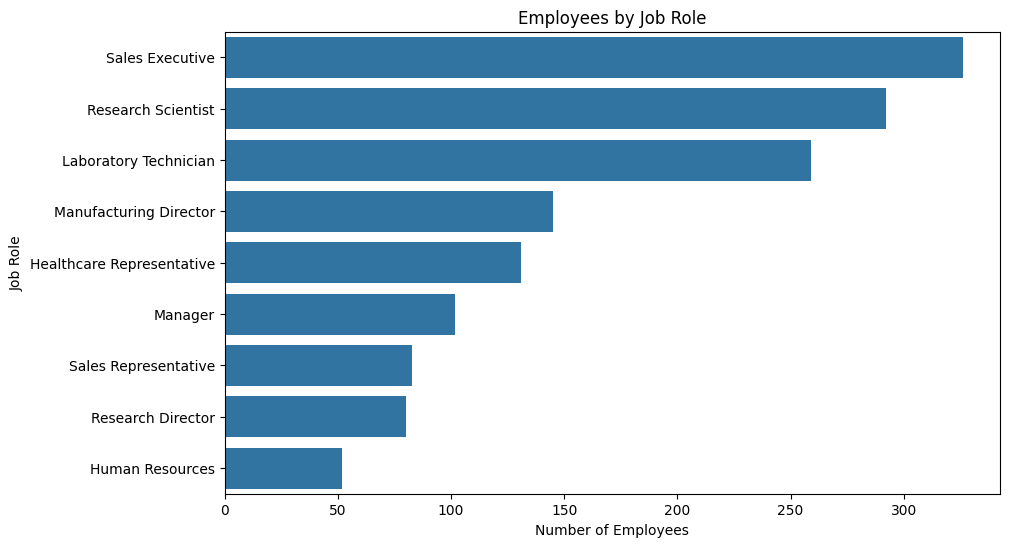

In [61]:
# Employees by Job Role

plt.figure(figsize=(10,6))

sns.countplot(
    data=df,
    y='JobRole',
    order=df['JobRole'].value_counts().index
)

plt.title('Employees by Job Role')
plt.xlabel('Number of Employees')
plt.ylabel('Job Role')
plt.show()

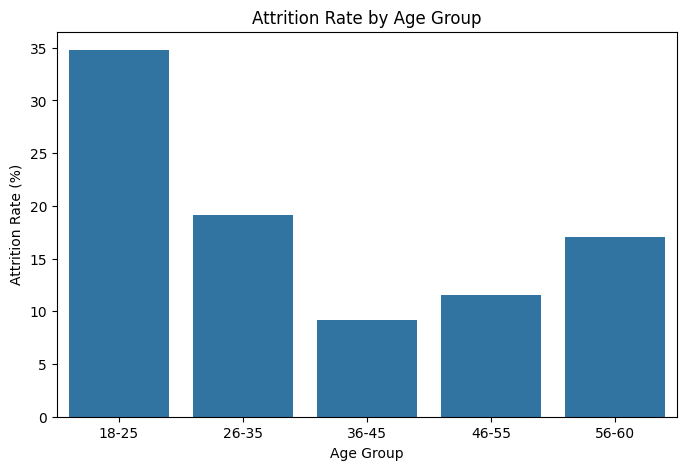

In [62]:
# Attrition Rate by Age Group

df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[18, 25, 35, 45, 55, 60],
    labels=['18-25', '26-35', '36-45', '46-55', '56-60']
)

age_attrition = (
    df.groupby('AgeGroup', observed=False)['Attrition']
      .apply(lambda x: (x == 'Yes').mean() * 100)
      .reset_index(name='AttritionRate')
)

plt.figure(figsize=(8,5))

sns.barplot(
    data=age_attrition,
    x='AgeGroup',
    y='AttritionRate'
)

plt.title('Attrition Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Attrition Rate (%)')
plt.show()

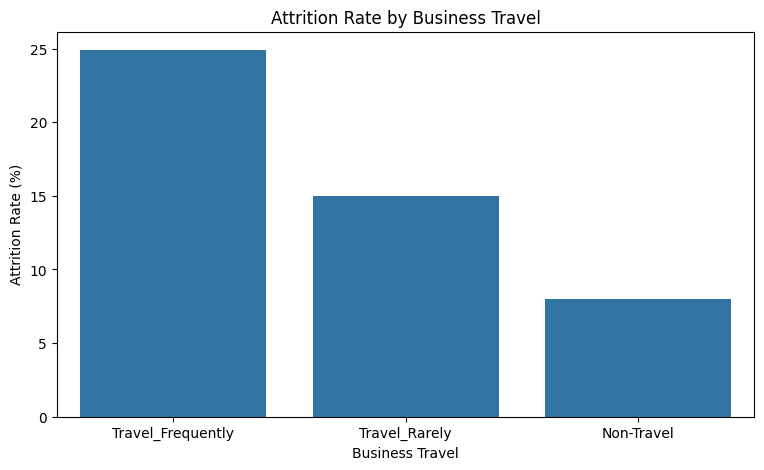

In [63]:
# Attrition Rate by Business Travel

travel_attrition = (
    df.groupby('BusinessTravel')['Attrition']
      .apply(lambda x: (x == 'Yes').mean() * 100)
      .reset_index(name='AttritionRate')
      .sort_values('AttritionRate', ascending=False)
)

plt.figure(figsize=(9,5))

sns.barplot(
    data=travel_attrition,
    x='BusinessTravel',
    y='AttritionRate'
)

plt.title('Attrition Rate by Business Travel')
plt.xlabel('Business Travel')
plt.ylabel('Attrition Rate (%)')
plt.show()

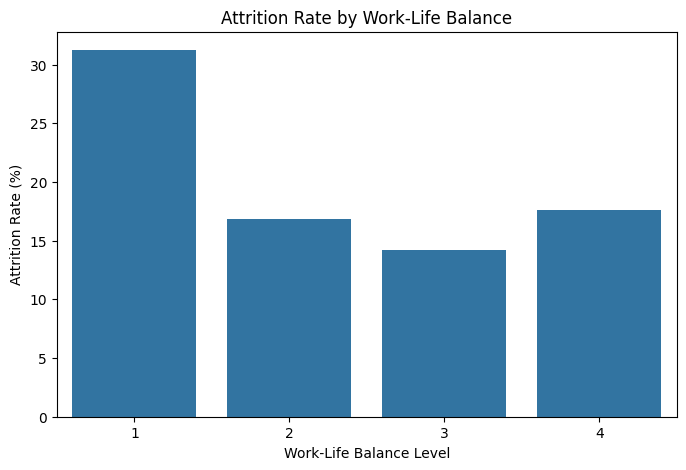

In [64]:
# Attrition Rate by Work-Life Balance

worklife_attrition = (
    df.groupby('WorkLifeBalance')['Attrition']
      .apply(lambda x: (x == 'Yes').mean() * 100)
      .reset_index(name='AttritionRate')
)

plt.figure(figsize=(8,5))

sns.barplot(
    data=worklife_attrition,
    x='WorkLifeBalance',
    y='AttritionRate'
)

plt.title('Attrition Rate by Work-Life Balance')
plt.xlabel('Work-Life Balance Level')
plt.ylabel('Attrition Rate (%)')
plt.show()

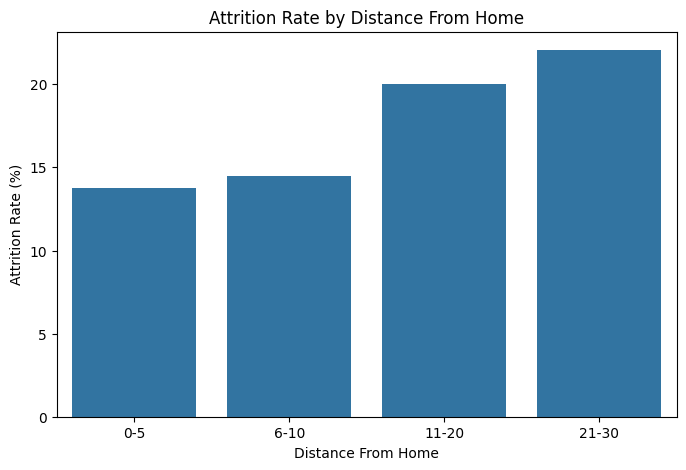

In [65]:
# Attrition Rate by Distance From Home

df['DistanceGroup'] = pd.cut(
    df['DistanceFromHome'],
    bins=[0, 5, 10, 20, 30],
    labels=['0-5', '6-10', '11-20', '21-30']
)

distance_attrition = (
    df.groupby('DistanceGroup', observed=False)['Attrition']
      .apply(lambda x: (x == 'Yes').mean() * 100)
      .reset_index(name='AttritionRate')
)

plt.figure(figsize=(8,5))

sns.barplot(
    data=distance_attrition,
    x='DistanceGroup',
    y='AttritionRate'
)

plt.title('Attrition Rate by Distance From Home')
plt.xlabel('Distance From Home')
plt.ylabel('Attrition Rate (%)')
plt.show()

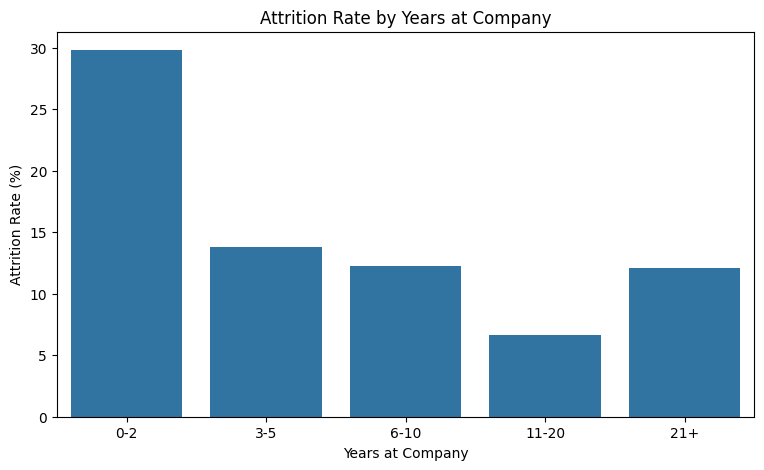

In [66]:
# Attrition Rate by Years at Company

df['YearsAtCompanyGroup'] = pd.cut(
    df['YearsAtCompany'],
    bins=[-1, 2, 5, 10, 20, 40],
    labels=['0-2', '3-5', '6-10', '11-20', '21+']
)

years_attrition = (
    df.groupby('YearsAtCompanyGroup', observed=False)['Attrition']
      .apply(lambda x: (x == 'Yes').mean() * 100)
      .reset_index(name='AttritionRate')
)

plt.figure(figsize=(9,5))

sns.barplot(
    data=years_attrition,
    x='YearsAtCompanyGroup',
    y='AttritionRate'
)

plt.title('Attrition Rate by Years at Company')
plt.xlabel('Years at Company')
plt.ylabel('Attrition Rate (%)')
plt.show()

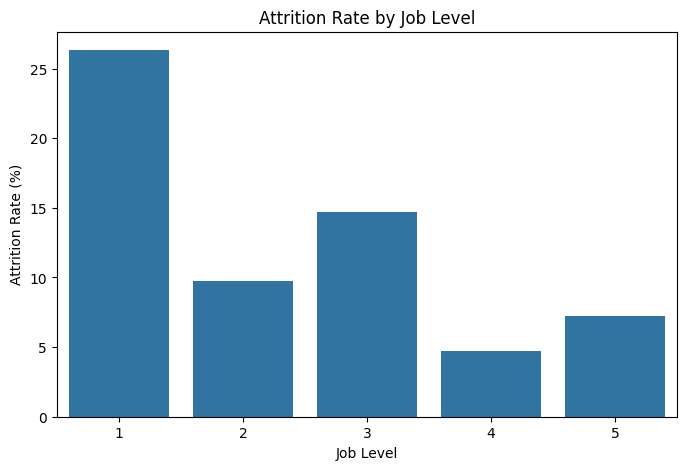

In [67]:
# Attrition Rate by Job Level

joblevel_attrition = (
    df.groupby('JobLevel')['Attrition']
      .apply(lambda x: (x == 'Yes').mean() * 100)
      .reset_index(name='AttritionRate')
)

plt.figure(figsize=(8,5))

sns.barplot(
    data=joblevel_attrition,
    x='JobLevel',
    y='AttritionRate'
)

plt.title('Attrition Rate by Job Level')
plt.xlabel('Job Level')
plt.ylabel('Attrition Rate (%)')
plt.show()

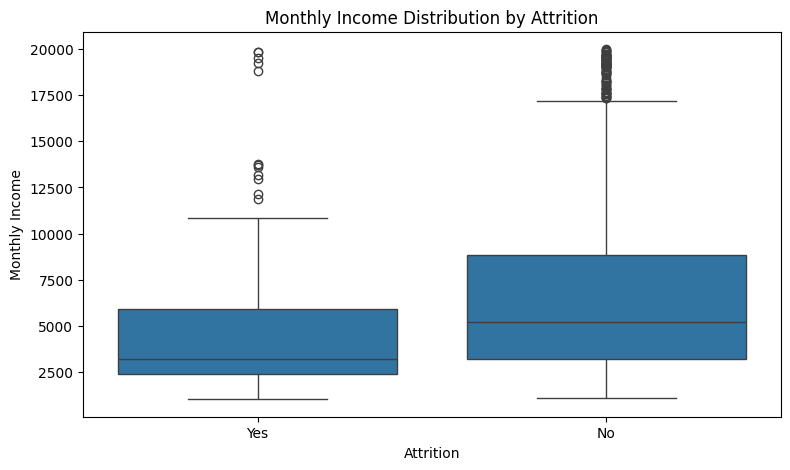

In [68]:
# Monthly Income Distribution by Attrition

plt.figure(figsize=(9,5))

sns.boxplot(
    data=df,
    x='Attrition',
    y='MonthlyIncome'
)

plt.title('Monthly Income Distribution by Attrition')
plt.xlabel('Attrition')
plt.ylabel('Monthly Income')
plt.show()

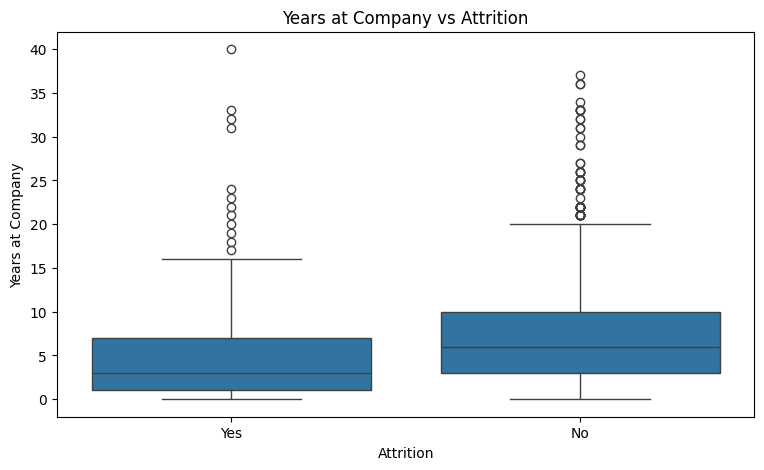

In [69]:
# Years at Company vs Attrition

plt.figure(figsize=(9,5))

sns.boxplot(
    data=df,
    x='Attrition',
    y='YearsAtCompany'
)

plt.title('Years at Company vs Attrition')
plt.xlabel('Attrition')
plt.ylabel('Years at Company')
plt.show()

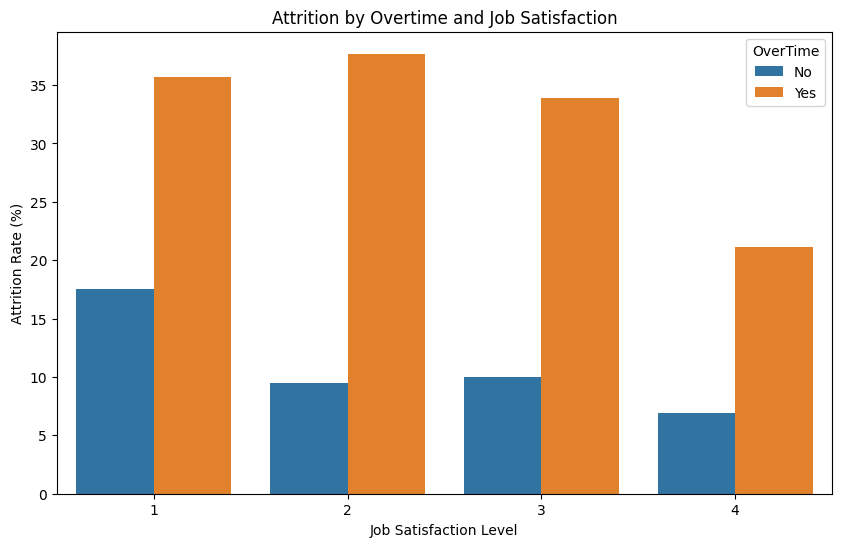

In [70]:
# Attrition by Overtime and Job Satisfaction

overtime_satisfaction = (
    df.groupby(['OverTime', 'JobSatisfaction'])['Attrition']
      .apply(lambda x: (x == 'Yes').mean() * 100)
      .reset_index(name='AttritionRate')
)

plt.figure(figsize=(10,6))

sns.barplot(
    data=overtime_satisfaction,
    x='JobSatisfaction',
    y='AttritionRate',
    hue='OverTime'
)

plt.title('Attrition by Overtime and Job Satisfaction')
plt.xlabel('Job Satisfaction Level')
plt.ylabel('Attrition Rate (%)')
plt.legend(title='OverTime')
plt.show()

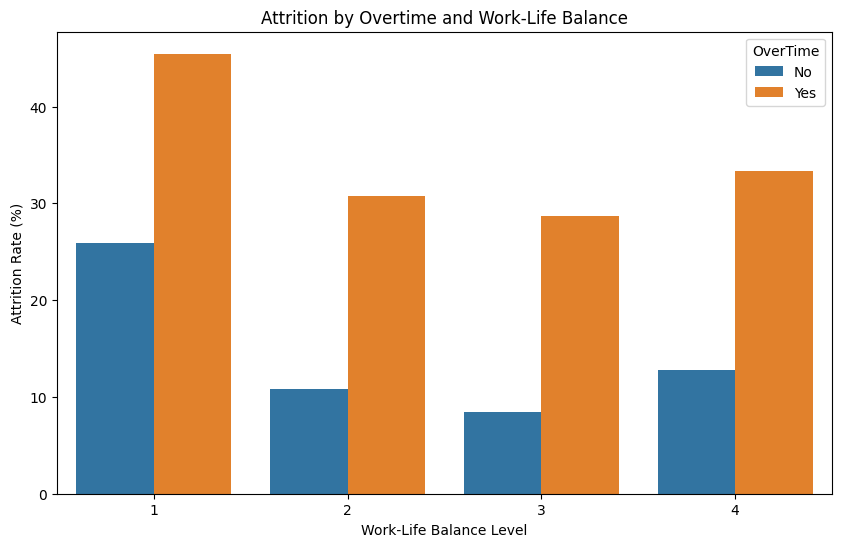

In [71]:
# Attrition by Overtime and Work-Life Balance

overtime_worklife = (
    df.groupby(['OverTime', 'WorkLifeBalance'])['Attrition']
      .apply(lambda x: (x == 'Yes').mean() * 100)
      .reset_index(name='AttritionRate')
)

plt.figure(figsize=(10,6))

sns.barplot(
    data=overtime_worklife,
    x='WorkLifeBalance',
    y='AttritionRate',
    hue='OverTime'
)

plt.title('Attrition by Overtime and Work-Life Balance')
plt.xlabel('Work-Life Balance Level')
plt.ylabel('Attrition Rate (%)')
plt.legend(title='OverTime')
plt.show()

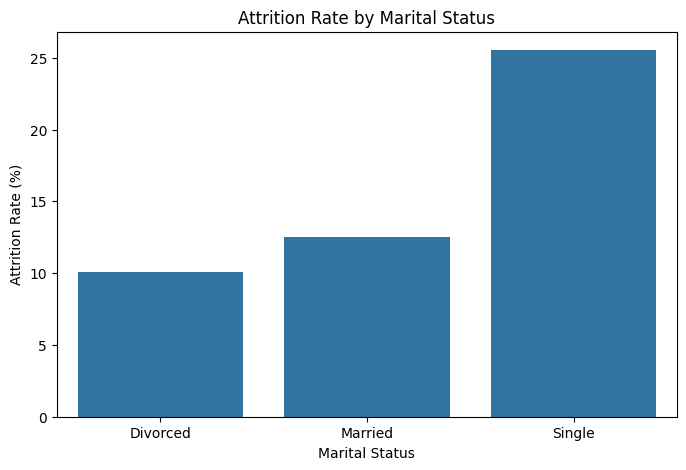

In [72]:
# Attrition Rate by Marital Status

marital_attrition = (
    df.groupby('MaritalStatus')['Attrition']
      .apply(lambda x: (x == 'Yes').mean() * 100)
      .reset_index(name='AttritionRate')
)

plt.figure(figsize=(8,5))

sns.barplot(
    data=marital_attrition,
    x='MaritalStatus',
    y='AttritionRate'
)

plt.title('Attrition Rate by Marital Status')
plt.xlabel('Marital Status')
plt.ylabel('Attrition Rate (%)')
plt.show()

In [79]:
# Key Attrition Findings

print("Overall Attrition Rate:",
      round((df['Attrition'] == 'Yes').mean() * 100, 2), "%")

print("\nAttrition Rate by Overtime:")
print(
    df.groupby('OverTime')['Attrition']
      .apply(lambda x: round((x == 'Yes').mean() * 100, 2))
)

print("\nAttrition Rate by Job Role:")
print(
    df.groupby('JobRole')['Attrition']
      .apply(lambda x: round((x == 'Yes').mean() * 100, 2))
      .sort_values(ascending=False)
)

print("\nAverage Monthly Income:")
print(
    df.groupby('Attrition')['MonthlyIncome']
      .mean()
      .round(2)
)

print("\nAverage Age:")
print(
    df.groupby('Attrition')['Age']
      .mean()
      .round(2)
)

print("\nAttrition Rate by Age Group:")
print(age_attrition.round(2))

print("\nAttrition Rate by Years at Company:")
print(years_attrition.round(2))

Overall Attrition Rate: 16.12 %

Attrition Rate by Overtime:
OverTime
No     10.44
Yes    30.53
Name: Attrition, dtype: float64

Attrition Rate by Job Role:
JobRole
Sales Representative         39.76
Laboratory Technician        23.94
Human Resources              23.08
Sales Executive              17.48
Research Scientist           16.10
Manufacturing Director        6.90
Healthcare Representative     6.87
Manager                       4.90
Research Director             2.50
Name: Attrition, dtype: float64

Average Monthly Income:
Attrition
No     6832.74
Yes    4787.09
Name: MonthlyIncome, dtype: float64

Average Age:
Attrition
No     37.56
Yes    33.61
Name: Age, dtype: float64

Attrition Rate by Age Group:
  AgeGroup  AttritionRate
0    18-25          34.78
1    26-35          19.14
2    36-45           9.19
3    46-55          11.50
4    56-60          17.02

Attrition Rate by Years at Company:
  YearsAtCompanyGroup  AttritionRate
0                 0-2          29.82
1             

## Key Findings and Business Insights

### Key Findings

* The overall employee attrition rate is **16.12%**.
* Employees working overtime had a higher attrition rate (**30.53%**) compared with employees who did not work overtime (**10.44%**).
* **Sales Representatives** had the highest attrition rate (**39.76%**) among the job roles analyzed.
* Employees who left the organization had a lower average monthly income (**4,787.09**) compared with employees who stayed (**6,832.74**).
* The average age of employees who left was **33.61 years**, compared with **37.56 years** for employees who stayed.
* The **18–25 age group** had the highest attrition rate (**34.78%**), followed by the **26–35 age group** (**19.14%**).
* Employees with **0–2 years at the company** had an attrition rate of **29.82%**, while employees with **11–20 years** had a lower rate of **6.67%**.

### Business Insights

The analysis shows noticeable differences in attrition rates across several employee and workplace factors, including **overtime, job role, age, monthly income, and years at the company**.

Higher attrition rates were observed among employees who worked overtime, younger employees, and employees with shorter tenure. Attrition also varied considerably across job roles, with Sales Representatives showing the highest rate among the roles analyzed.

These findings can help HR teams identify areas for further investigation, such as **workload, employee experience, compensation, career growth, and employee retention**.


## Conclusion

This project analyzed employee attrition using Python, Pandas, Matplotlib, and Seaborn.

The analysis identified noticeable differences in attrition rates across factors such as **overtime, job role, age, monthly income, and years at the company**. Higher attrition rates were observed among employees working overtime, younger employees, employees with shorter tenure, and certain job roles.

The analysis also shows that employees who left had lower average monthly income and lower average age compared with employees who stayed.

These findings provide a useful overview of employee attrition patterns and highlight areas that HR teams can investigate further, including **workload, compensation, career growth, employee experience, and retention**.

Overall, the project demonstrates the use of **data cleaning, exploratory data analysis, statistical analysis, and visualization** to generate meaningful HR insights from employee data.
